<a href="https://colab.research.google.com/github/manyaAM123/deep_learning/blob/main/mlp_exp2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense


# 2. Load California Housing Dataset
housing = fetch_california_housing(as_frame=True)

X = housing.data
y = housing.target

print("Dataset loaded successfully!")
print("Number of samples:", X.shape[0])
print("Number of features:", X.shape[1])

print("\nFirst 5 rows:")
print(X.head())


# 3. Split Dataset into Training and Testing Data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("\nTraining samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


# 4. Feature Scaling
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


# 5. Build MLP Model
model = Sequential([
    Dense(128, activation='relu', input_shape=(8,)),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(1,activation='linear')
])


# 6. Display Model Architecture
model.summary()


# 7. Compile the Model
model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)


# 8. Train the Model
history = model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=8,
    validation_split=0.2,
    verbose=1
)


# 9. Evaluate the Model
loss, mae = model.evaluate(X_test, y_test, verbose=0)

print("\nModel Evaluation")
print("-----------------------")
print("Test MSE:", loss)
print("Test MAE:", mae)


# 10. Make Predictions
y_pred = model.predict(X_test)

y_pred = y_pred.flatten()

print("\nFirst 10 Predictions")
print("-----------------------")

for i in range(10):
    print("Actual:", y_test.iloc[i],
          "Predicted:", y_pred[i])


# 11. Calculate Performance Metrics
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\nPerformance Metrics")
print("-----------------------")
print("Mean Squared Error (MSE):", mse)
print("Mean Absolute Error (MAE):", mae)
print("R2 Score:", r2)
print("approximate percentage of:",r2*100,"%")



Dataset loaded successfully!
Number of samples: 20640
Number of features: 8

First 5 rows:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  
0    -122.23  
1    -122.22  
2    -122.24  
3    -122.25  
4    -122.25  

Training samples: 16512
Testing samples: 4128


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_16 (Dense)                │ (None, 128)            │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,521 (45.00 KB)

 Trainable params: 11,521 (45.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
1652/1652 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - loss: 0.5172 - mae: 0.4979 - val_loss: 0.3865 - val_mae: 0.4336
Epoch 2/15
1652/1652 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.3677 - mae: 0.4254 - val_loss: 0.3799 - val_mae: 0.4293
Epoch 3/15
1652/1652 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 0.3438 - mae: 0.4061 - val_loss: 0.3361 - val_mae: 0.4078
Epoch 4/15
1652/1652 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.3306 - mae: 0.3913 - val_loss: 0.3807 - val_mae: 0.4518
Epoch 5/15
1652/1652 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.3104 - mae: 0.3860 - val_loss: 0.3231 - val_mae: 0.3947
Epoch 6/15
1652/1652 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - loss: 0.3031 - mae: 0.3805 - val_loss: 0.3194 - val_mae: 0.3847
Epoch 7/15
1652/1652 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.2966 - mae: 0.3750 - val_loss: 0.3254 - val_mae: 0.3916
Epoch 8/15
1652/1652 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - loss: 0.2979 - mae: 0.3703 - val_loss: 0.3131 - val_mae: 0.3782
Epoch 9/15
1652/1652 ━━━━━━━━━━━━━━━━━━

Trial 10 Complete [00h 00m 09s]
val_accuracy: 1.0

Best val_accuracy So Far: 1.0
Total elapsed time: 00h 01m 30s

Best Hyperparameters
----------------------------
Number of hidden layers: 2
Number of neurons: 80
Dropout rate: 0.2
Optimizer: adam
Learning rate: 0.001

Best Model Architecture


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 14 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 80)             │           400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 80)             │         6,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 80)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           243 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,123 (27.82 KB)

 Trainable params: 7,123 (27.82 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - accuracy: 0.9375 - loss: 0.1613 - val_accuracy: 1.0000 - val_loss: 0.1286
Epoch 2/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9583 - loss: 0.1702 - val_accuracy: 1.0000 - val_loss: 0.1293
Epoch 3/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9479 - loss: 0.1572 - val_accuracy: 1.0000 - val_loss: 0.1198
Epoch 4/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9583 - loss: 0.1556 - val_accuracy: 1.0000 - val_loss: 0.1136
Epoch 5/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9479 - loss: 0.1375 - val_accuracy: 1.0000 - val_loss: 0.1029
Epoch 6/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.9688 - loss: 0.1311 - val_accuracy: 1.0000 - val_loss: 0.0950
Epoch 7/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9583 - loss: 0.1323 - val_accuracy: 1.0000 - val_loss: 0.0817
Epoch 8/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.9479 - loss: 0.1327 - val_accuracy: 1.0000 - val_loss: 0.0739


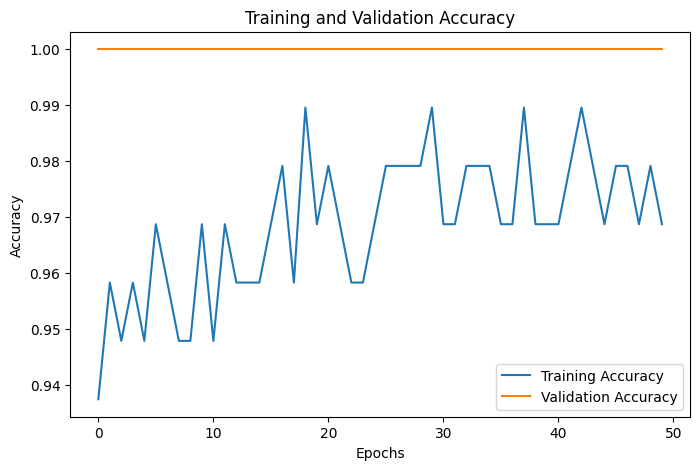

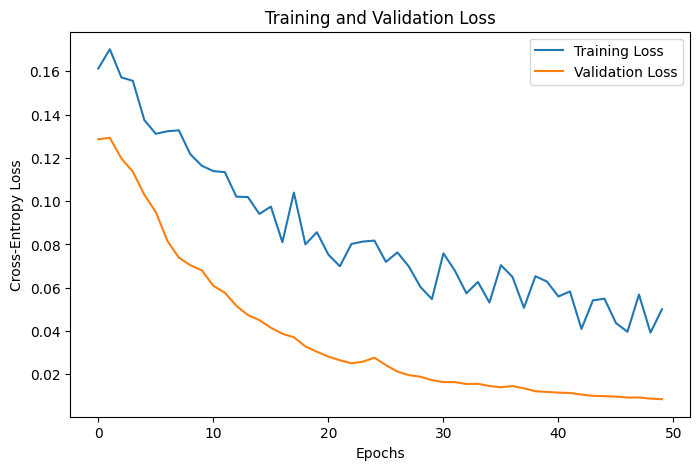

In [ ]:


!pip install keras-tuner
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam, SGD

import keras_tuner as kt


# ============================================================
# 2. Load Iris Dataset
# ============================================================

iris = load_iris()

X = iris.data
y = iris.target

print("Dataset loaded successfully!")
print("Input shape:", X.shape)
print("Number of classes:", len(np.unique(y)))

print("\nFeature names:")
print(iris.feature_names)

print("\nTarget names:")
print(iris.target_names)


# ============================================================
# 3. Split Dataset
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


# ============================================================
# 4. Feature Scaling
# ============================================================

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


# ============================================================
# 5. Define Hyperparameter Model
# ============================================================

def build_model(hp):

    model = Sequential()

    # Number of hidden layers
    num_layers = hp.Int(
        'num_layers',
        min_value=1,
        max_value=3,
        step=1
    )

    # First hidden layer
    units = hp.Int(
        'units',
        min_value=16,
        max_value=128,
        step=16
    )

    model.add(
        Dense(
            units=units,
            activation='relu',
            input_shape=(4,)
        )
    )

    # Additional hidden layers
    for i in range(num_layers - 1):

        model.add(
            Dense(
                units=units,
                activation='relu'
            )
        )

    # Dropout rate
    dropout_rate = hp.Float(
        'dropout_rate',
        min_value=0.0,
        max_value=0.5,
        step=0.1
    )

    model.add(Dropout(dropout_rate))

    # Output layer
    model.add(
        Dense(
            3,
            activation='softmax'
        )
    )

    # Optimizer
    optimizer_name = hp.Choice(
        'optimizer',
        values=['adam', 'sgd']
    )

    # Learning rate
    learning_rate = hp.Choice(
        'learning_rate',
        values=[0.001, 0.01, 0.0001]
    )

    if optimizer_name == 'adam':

        optimizer = Adam(
            learning_rate=learning_rate
        )

    else:

        optimizer = SGD(
            learning_rate=learning_rate,
            momentum=0.9
        )

    # Compile model
    model.compile(
        optimizer=optimizer,
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model


# ============================================================
# 6. Create Keras Tuner
# ============================================================

tuner = kt.RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=10,
    directory='keras_tuner',
    project_name='iris_mlp'
)


# ============================================================
# 7. Display Search Space
# ============================================================

tuner.search_space_summary()


# ============================================================
# 8. Hyperparameter Search
# ============================================================

tuner.search(
    X_train,
    y_train,
    epochs=50,
    validation_split=0.2,
    batch_size=16,
    verbose=1
)


# ============================================================
# 9. Display Best Hyperparameters
# ============================================================

best_hps = tuner.get_best_hyperparameters(
    num_trials=1
)[0]

print("\nBest Hyperparameters")
print("----------------------------")

print(
    "Number of hidden layers:",
    best_hps.get('num_layers')
)

print(
    "Number of neurons:",
    best_hps.get('units')
)

print(
    "Dropout rate:",
    best_hps.get('dropout_rate')
)

print(
    "Optimizer:",
    best_hps.get('optimizer')
)

print(
    "Learning rate:",
    best_hps.get('learning_rate')
)


# ============================================================
# 10. Get Best Model
# ============================================================

best_model = tuner.get_best_models(
    num_models=1
)[0]

print("\nBest Model Architecture")
best_model.summary()


# ============================================================
# 11. Train Best Model
# ============================================================

history = best_model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)


# ============================================================
# 12. Evaluate Model
# ============================================================

loss, accuracy = best_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("\nModel Evaluation")
print("----------------------------")
print("Test Loss:", loss)
print("Test Accuracy:", accuracy)


# ============================================================
# 13. Make Predictions
# ============================================================

y_probability = best_model.predict(X_test)

y_pred = np.argmax(
    y_probability,
    axis=1
)


# ============================================================
# 14. Calculate Accuracy
# ============================================================

accuracy = accuracy_score(
    y_test,
    y_pred
)

print("\nFinal Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")


# ============================================================
# 15. Confusion Matrix
# ============================================================

cm = confusion_matrix(
    y_test,
    y_pred
)

print("\nConfusion Matrix:")
print(cm)


# ============================================================
# 16. Classification Report
# ============================================================

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=iris.target_names
    )
)


# ============================================================
# 17. Plot Training Accuracy
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")

plt.legend()
plt.show()


# ============================================================
# 18. Plot Training Loss
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.xlabel("Epochs")
plt.ylabel("Cross-Entropy Loss")
plt.title("Training and Validation Loss")

plt.legend()
plt.show()